# Confort 15 example: Kilauea H$_2$O sensitivity and Etna crystal aspect ratio sensitivity

This notebook illustrates the sensitivity of conduit flow properties to dissolved water content
using a Kilauean composition from Mastin (2002) and crystal aspect ratio using Etna composition from Camagnola et al. (2016).

In [2]:
import pandas as pd
import subprocess
import os
import shutil
import matplotlib.pyplot as plt

#Might need updating if your path to the Confort 15 code is different.
EXECUTABLE = '/home/jovyan/Conflow/conflow'

#This line is needed for running the Fortran code
yes = b'y\ny\n'

## Helper functions

### Select Output Parameters

Below is the complete list of possible outputs. 

1. x-sectional area (m2)
2. Mach number
3. pressure (MPa)
4. log Reynolds number
5. mixture density
6. time (s) since entering conduit
7. velocity (m/s)
8. volume fraction gas
9. log viscosity (Pa s)
10. z (depth, meters)
11. d(x-s area)/dz, meters
12. log pressure (MPa)
13. dpdz (pressure gradient, Pa/m)
14. log dz (vert. step size, m)
15. f (friction factor)
16. gamma (Cp/Cv for gas phase)
17. mf (mass fraction exsolved gas)
18. mm (mass fraction magma)
19. r (Universal Gas const.)
20. rhof (gas density)
21. sv (sonic velocity (m/s)
22. temperature (C)
23. enthalpy of mixture (kJ/kg)
24. cp (sp. heat) of gas (kJ/kg C)
25. conduit radius(m)
26. dissolved h2o (wt%)
27. cp (sp. heat) of melt (kJ/kg C)

Confort 15 can output up to 7 variables at a time. The choices list below controls which variables are written to the output file. Each number corresponds to a variable in the numbered list above (e.g., 10 = depth, 7 = velocity).

The order of numbers in "choices" below also determines the output column order, which is how the model knows where to write each variable. You do not need to change this list for the exercises below, but if you want to explore additional variables (e.g., add dissolved H$_2$O by including 26), replace one of the existing numbers with the new one. You can only have 7 at a time.

The headers list directly below translates those column numbers into readable column names for the pandas DataFrame, so any change to "choices" will automatically apply to "headers".

In [6]:
#Change the list of choices to change which variables are returned. Choose based on the numbered list above.
choices = [10, 2, 3, 8, 9, 22, 7]

all_headers = [
    'area', 'mach', 'p (MPa)', 'log Re', 'density', 'time (s)',
    'vel (m/s)', 'vfgas', 'log visc', 'z (m)', 'dadz', 'log(p)',
    'dpdz', 'dz (m)', 'f', 'gamma', 'mgas/mtot', 'mmag/mtot',
    'R (J/m K)', 'gas dens', 'sonic vel', 'temp(c)', 'h (kJ/kg)',
    'cp', 'radius', 'dh2o(wt%)', 'cm (J/kgK)'
]

headers = [all_headers[i - 1] for i in choices]

In [7]:
def read_output(path):
    """Read the OUTPUT TABLE block from a Confort 15 output file.
    The full depth profile is written once at the end of a run under 'OUTPUT TABLE',
    """
    with open(path) as f:
        lines = f.readlines()
    skip = None
    for i, l in enumerate(lines):
        if 'OUTPUT TABLE' in l:
            skip = i + 2   # OUTPUT TABLE line, then header line, then data
            break
    if skip is None:
        raise ValueError('No OUTPUT TABLE found in ' + path)
    df = pd.read_csv(path, skiprows=skip, sep=r'\s+',
                     usecols=range(1, 8), names=headers,
                     on_bad_lines='skip')
    df = df.apply(pd.to_numeric, errors='coerce').dropna()
    return df


def parse_frag_depth(path, frag_threshold=0.75):
    """Return the depth (m) at which vfgas first exceeds frag_threshold, or NaN."""
    df = read_output(path)
    above = df[df['vfgas'] >= frag_threshold]
    if len(above) == 0:
        return float('nan')
    return abs(above.iloc[0]['z (m)'])


notes = (
    '\nNOTES ON INPUT PARAMETERS:\n'
    '*iteration #=2 if the velocity is to be adjusted automatically to reach\n'
    '            sonic velocities at the exit (valid only if icalc= 10 ), or\n'
    '         1 if no adjustment is desired.\n'
    '**vesiculation p.= 2 if gas exsolution is to stop after fragmentation\n'
    '               1 if not\n'
    '***1=vfgas = constant ****if no dp/dt calculation using Toramaru formulations is desired, please write 0\n'
    '2=mixture viscosity*strain rate > 25 GPa\n'
    '3=mixture viscosity*strain rate > 0.01*elastic modulus of celluar solid\n'
    '4=fragmentation at eta * dvdz * stress concentration around bubble wall > 250 MPa\n'
)

outputs = (
    '\nOutput Parameters:\n'
    'List of variables to be written out. Enter a number in the\n'
    'first column indicating the column # where this variable will be written\n'
    'in the output file.  You can write out up to seven variables.'
)

In [8]:
def make_input(params):
    """Write conin.txt based on input parameters for running Confort 15."""
    p = params
    pars = (
        f'INPUT PARAMETERS:        PARAMETER EXPLANATIONS:\n'
        f'data.out                  name of output file\n'
        f'{p["diam_pgrd"]}                          specify conduit diameter (diam) or pressure gradient (pgrd)\n'
        f'{p["ipa"]}, {p["fpa"]}                   initial, final pressure (MPa)\n'
        f' {p["iter_param"]}                            iteration number*\n'
        f'{p["init_v"]}                          initial velocity (m/s)\n'
        f'{p["init_temp"]}     {p["var_const_t"]}                    initial temperature (C), itemp (1=const T, 2=variable T)\n'
        f'{p["sphoc"]}                        sp. heat of crystals (J/kg K)\n'
        f'{p["water_percent"]}                          h2o content (wt%)\n'
        f' {p["vesi_param"]}                            vesiculation parameter**\n'
        f'{p["init_depth"]}, {p["final_depth"]}                   initial, final depth (m)\n'
        f'{p["conduit_diam_bottom"]}, {p["conduit_diam_top"]}                  conduit diameter (m) at bottom, top\n'
        f'{p["gravity"]}                          gravitational acceleration (m/s2)\n'
        f'{p["siO2_percent"]}                         Weight % SiO2 (anhydrous)\n'
        f'{p["al2Oe_percent"]}                         Weight % Al2O3 (anhydrous)\n'
        f'{p["fe2O3_percent"]}                          Weight % Fe2O3 (anhydrous)\n'
        f'{p["feO_percent"]}                          Weight % FeO (anhydrous)\n'
        f'{p["mnO_percent"]}                          Weight % MnO (anhydrous)\n'
        f'{p["mgO_percent"]}                          Weight % MgO (anhydrous)\n'
        f'{p["caO_percent"]}                          Weight % CaO (anhydrous)\n'
        f'{p["tiO2_percent"]}                          Weight % TiO2 (anhydrous)\n'
        f'{p["na2O_percent"]}                          Weight % Na2O (anhydrous)\n'
        f'{p["k2O_percent"]}                          Weight % K2O (anhydrous)\n'
        f'{p["p2O5"]}                          Weight % P2O5 (anhydrous)\n'
        f'{p["f2O1"]}                          Weight % F2O-1 (anhydrous)\n'
        f'{p["crystal_percent_1"]}, {p["crystal_density_1"]}, {p["crystal_ar_1"]}                   (plg)   PHASE 1: volume % crystals, crystal density (kg/m3), ar\n'
        f'{p["crystal_percent_2"]}, {p["crystal_density_2"]}, {p["crystal_ar_2"]}       \t      (cpx)    PHASE 2: volume % crystals, crystal density (kg/m3), ar\n'
        f'{p["crystal_percent_3"]}, {p["crystal_density_3"]}, {p["crystal_ar_3"]}\t              (ox)    PHASE 3: volume % crystals, crystal density (kg/m3), ar\n'
        f'{p["bubble_number"]}  \t              bubble number density for smallest vesicle sizes (cm-3)****\n'
        f'{p["surface_tension"]}\t\t\t      surface tension (N/m)\n'
        f'{p["diff_vol"]}\t\t\t      diffusivity volatile D (m2/s)\n'
        f'{p["fraction_fragment"]}                          volume fraction gas at which fragmentation occurs\n'
        f' {p["frag_criterion"]}                            fragmentation criterion (1=vfgas, 2=strain-rate)\n'
    )

    all_var_lines = [
        '         x-sectional area (m2)',
        '         Mach number',
        '         pressure (MPa)',
        '         log Reynolds number',
        '         mixture density',
        '         time (s) since entering conduit',
        '         velocity (m/s)',
        '         volume fraction gas',
        '         log viscosity (Pa s)',
        '         z (depth, meters)',
        '         d(x-s area)/dz, meters',
        '         log pressure (MPa)',
        '         dpdz (pressure gradient, Pa/m)',
        '         log dz (vert. step size, m)',
        '         f (friction factor)',
        '         gamma (Cp/Cv for gas phase)',
        '         mf (mass fraction exsolved gas)',
        '         mm (mass fraction magma)',
        '         r (Universal Gas const. * n)',
        '         rhof (gas density)',
        '         sv (sonic velocity (m/s)',
        '         temperature (C)',
        '         enthalpy of mixture (kJ/kg)',
        '         cp (sp. heat) of gas (kJ/kg C)',
        '         conduit radius(m)',
        '         dissolved h2o (wt%)',
        '         cp (sp. heat) of melt (kJ/kg C)',
    ]

    altered_lines = []
    for idx, line in enumerate(all_var_lines):
        var_num = idx + 1  # 1-based variable number
        if var_num in choices:
            col = choices.index(var_num) + 1  # output column number (1–7)
            altered_lines.append(str(col) + line)
        else:
            altered_lines.append(line)

    altered = '\n'.join(altered_lines)

    with open('conin.txt', 'w') as f:
        f.write(pars + notes + outputs + '\n' + altered)

# Part 1: Kilauea H$_2$O sensitivity

We run the model four times, varying only the H$_2$O content (0.25, 0.50, 1.00, 1.31 wt%).
All other parameters are held constant. This allows direct comparison with Table 2 of Mastin (2002).

**Reference**: Mastin, L. G. (2002). Insights into volcanic conduit flow from an open-source numerical model. Geochemistry, Geophysics, Geosystems. https://doi.org/10.1029/2001GC000192

## Input parameters from Mastin (2002):
Kilauean basalt composition from Table 2

Conduit geometry: 4 m diameter, 1 km deep

Temperature: 1150 °C. Crystal content: 0 vol%



#### The only variable across runs is `water_percent`.

In [11]:
# Setting the input parameters for the simulation as a dictionary.
    
kilauea_params = {
    'diam_pgrd':           'diam',
    'ipa':                 27,      
    'fpa':                 0.1,
    'iter_param':          2,
    'init_v':              1,
    'init_temp':           1150, 
    'var_const_t':         2,
    'sphoc':               1702.5,
    'vesi_param':          1,
    'init_depth':          1000.0,
    'final_depth':         0.0,
    'conduit_diam_bottom':  4.0,    'conduit_diam_top': 4.0,
    'gravity':             9.81,
    'siO2_percent':        51.96,   'al2Oe_percent':    14.21,
    'feO_percent':         10.96,   'mgO_percent':       6.59,
    'caO_percent':         10.86,   'tiO2_percent':      2.53,
    'na2O_percent':        2.48,    'k2O_percent':       0.41,
    'fe2O3_percent':       0.00,
    'mnO_percent':         0.00,
    'p2O5':                0.00,
    'f2O1':                0.00,
    'crystal_percent_1':   0,   'crystal_density_1': 2900, 'crystal_ar_1': 3,
    'crystal_percent_2':   0,   'crystal_density_2': 3190, 'crystal_ar_2': 3,
    'crystal_percent_3':   0,   'crystal_density_3': 3190, 'crystal_ar_3': 1.76,
    'bubble_number':       2.8e15,
    'surface_tension':     0.035,
    'diff_vol':            2e-12,
    'fraction_fragment':   0.75,
    'frag_criterion':      1,
}

#Setting the H2O wt% to iterate through.
water_runs  = [0.25, 0.50, 1.00, 1.31]

## Run all four simulations

In [13]:
#The code below runs the model for each H2O wt%
dfs = {}
frag_depths = {}


for i, w in enumerate(water_runs):
    run_params = kilauea_params | {'water_percent': w}
    archive = f'run_{i}.out'
    print(f'Performing Run {i+1}: {w} wt% H2O')
    make_input(run_params)
    with open('conin.txt') as f:
        assert str(w) in f.read(), f'ERROR: {w} wt% H2O not found in conin.txt — check make_input()'
    p = subprocess.run(EXECUTABLE, shell=True, input=yes)
    if not os.path.exists('data.out'):
        print('  WARNING: data.out not found — check executable path')
        continue
    shutil.copy('data.out', archive)
    try:
        dfs[w] = read_output(archive)
        frag_depths[w] = parse_frag_depth(archive)
    except Exception as e:
        print(f'  Could not parse output: {e}')

print('\nAll runs complete.')

Performing Run 1: 0.25 wt% H2O
Confort version .
last revised Nov, 2014 by Larry G. Mastin and Silvia Campagnola
U.S. Geological Survey lgmastin@usgs.gov
Roma Tre University silvia.campagnola@hotmail.it


     You calculated the dpdt using Toramaru formulations.     Your resulting dpdt is:           0.6990E+00MPa/s
     Do you wish to continue? (y/n): making sure variables are entered correctly

          INPUT VALUES:

           input velocity =   1.0000 m/s
           magma density=  2671. kg/m3 (calculated)
           input temperature = 1150. degrees Celsius
           initial dissolved h2o= 0.250 wt %
           depth at base of conduit= 1000.0000 m
           depth at top of conduit=   -0.0000 m

          MAGMA COMPOSITION:

           51.960      SIO2 (wt% anhydrous)
           14.210      Al2O3
            0.000      Fe2O3
           10.960      FeO
            6.590      MgO
           10.860      CaO
            2.530      TiO2
            2.480      Na2O
            0.410 

## Results summary: H$_2$O wt% sensitivity

Compare exit conditions across runs.

In [15]:
print(f"{'H2O (wt%)':<12} {'Exit vel (m/s)':<18} {'Exit vf gas':<14} {'Frag. depth (m)'}")
for w in water_runs:
    ex = dfs[w].iloc[-1]
    print(f"{w:<12} {ex['vel (m/s)']:<18.1f} {ex['vfgas']:<14.3f} {frag_depths[w]:.1f}")

H2O (wt%)    Exit vel (m/s)     Exit vf gas    Frag. depth (m)
0.25         33.3               0.889          24.0
0.5          51.2               0.860          37.8
1.0          78.3               0.840          53.7
1.31         91.9               0.837          63.5


## Plotting

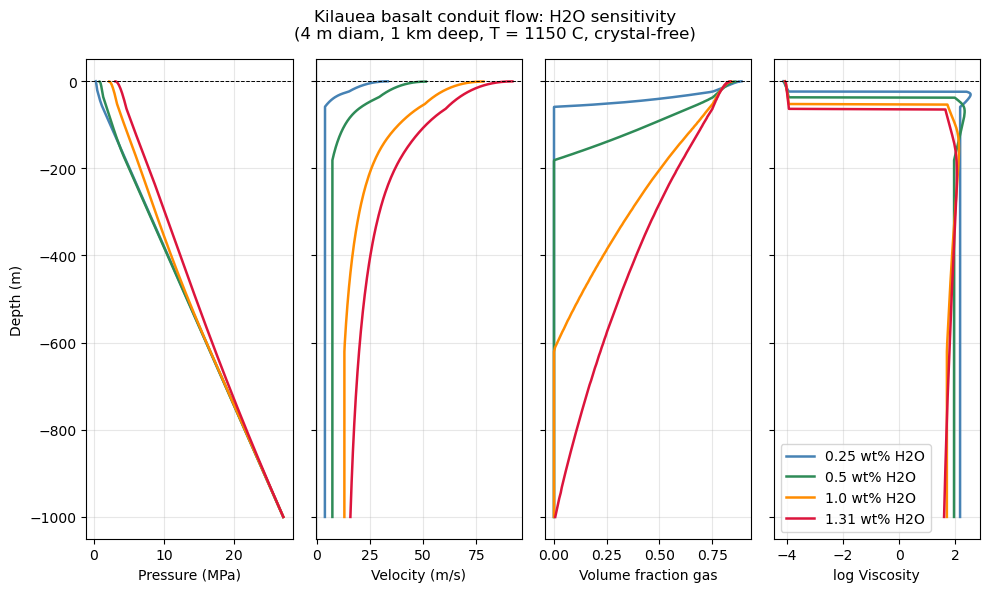

Figure saved as kilauea_H2O_sensitivity.png


In [17]:
plot_vars = [
    ('p (MPa)',   'Pressure (MPa)'),
    ('vel (m/s)', 'Velocity (m/s)'),
    ('vfgas',     'Volume fraction gas'),
    ('log visc',   'log Viscosity'),
]

w_colors = {0.25: 'steelblue', 0.50: 'seagreen', 1.00: 'darkorange', 1.31: 'crimson'}

fig, axes = plt.subplots(1, 4, figsize=(10, 6), sharey=True)
fig.suptitle(
    'Kilauea basalt conduit flow: H2O sensitivity\n'
    '(4 m diam, 1 km deep, T = 1150 C, crystal-free)',
    fontsize=12
)

# For each subplot, plot one line per H2O content
for ax, (var, xlabel) in zip(axes, plot_vars):
    for w, df in dfs.items():
        ax.plot(df[var], df['z (m)'], label=f'{w} wt% H2O', color=w_colors[w], linewidth=1.8)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3)
    ax.axhline(0, color='k', linewidth=0.7, linestyle='--')

axes[0].set_ylabel('Depth (m)', fontsize=10)
axes[3].legend(fontsize=10, loc='lower left')
plt.tight_layout()
plt.savefig('kilauea_H2O_sensitivity.png', dpi=150)
plt.show()
print('Figure saved as kilauea_H2O_sensitivity.png')

## Discussion questions: H$_2$O sensitivity

1. How does exit velocity scale with H$_2$O content?
2. How does fragmentation depth change? What physical processes drive this?

---
# Part 2: Etna crystal aspect ratio sensitivity

The original Conflow used the Einstein-Roscoe equation for crystal-bearing viscosity, which depends
only on crystal volume fraction and ignores crystal shape. Confort 15 replaces this with
the Vona et al. (2011) parameterization, which accounts for both crystal shape (aspect ratio)
and strain rate. Campagnola et al. (2016) show this produces up to 3.2 log units difference in
relative viscosity for the Etna 122 BC case. This is enough to switch the magma between effusive and
explosive behaviour.

We use the Etna 122 BC hawaiitic composition from Campagnola et al. (2016) Table 3.
Crystal content is fixed at 43 vol% (26 vol% plagioclase + 13 vol% clinopyroxene + 4 vol% olivine, combining phenocrysts and microlites), and aspect ratio is varied across four runs. The aspect ratio of the plagioclase phase is varied across four runs while cpx (AR = 3) and olivine (AR = 2) are held fixed.

| Run | Aspect ratio | Analogue | Conflow equivalent? |
|-----|-------------|----------|---------------------|
| 1   | 1           | Equant grains | ✓ Einstein-Roscoe |
| 2   | 3           | Blocky plagioclase | ✗ |
| 3   | 5           | Tabular plagioclase (Etna 122 BC mean) | ✗ |
| 4   | 8           | Elongate microlites | ✗ |

**Reference:** Campagnola et al. (2016). Confort 15 model of conduit dynamics: Applications to Pantelleria Green Tuff and Etna 122 BC eruptions. Contributions to Mineralogy and Petrology. https://doi.org/10.1007/s00410-016-1265-5


In [20]:
# Etna 122 BC parameters from Campagnola et al. (2016) Table 3
# Setting the input parameters for the simulation as a dictionary.

etna_base = {
    'diam_pgrd':           'diam',
    'iter_param': 1,
    'ipa': 150,  'fpa': 0.1,
    'init_v':              1,
    'init_temp': 1100,  
    'var_const_t':         2,
    'sphoc':               1702.5,
    'vesi_param':          1,
    'init_depth': 6000.0,  'final_depth':         0.0,
    'conduit_diam_bottom': 20.0,  'conduit_diam_top': 20.0,
    'gravity':             9.81,
    'water_percent': 1.85,
    'siO2_percent': 49.32,  'al2Oe_percent': 18.44,
    'fe2O3_percent': 7.80,  'feO_percent':    3.01,
    'mnO_percent':   0.18,  'mgO_percent':    2.78,
    'caO_percent':   9.39,  'tiO2_percent':   1.95,
    'na2O_percent':  4.18,  'k2O_percent':    1.72,
    'p2O5': 0.50,
    'f2O1': 0.00,
    # plg phenocrysts + microlites = 26 vol%
    'crystal_percent_1': 26,  'crystal_density_1': 2630,  'crystal_ar_1': 1,
    # clinopyroxene = 13%
    'crystal_percent_2': 13,  'crystal_density_2': 3190,  'crystal_ar_2': 3,
    # olivine = 4 vol%
    'crystal_percent_3': 4,   'crystal_density_3': 3190,  'crystal_ar_3': 2,
    'bubble_number':       2.8e15,
    'surface_tension':     0.035,
    'diff_vol':            2e-12,
    'fraction_fragment':   0.75,
    'frag_criterion':      1,
}

aspect_ratios = [1, 3, 5, 8]

## Run all four simulations

In [22]:
#The code below runs the model for each aspect ratio
dfs_ar = {}
frag_depths_ar = {}

for i, ar in enumerate(aspect_ratios):
    run_params = etna_base | {'crystal_ar_1': ar}
    archive = f'run_ar{ar}.out'
    print(f'Performing Run {i+1}: AR = {ar}')
    make_input(run_params)
    with open('conin.txt') as f:
        assert str(ar) in f.read(), f'ERROR: AR={ar} not found in conin.txt — check make_input()'
    p = subprocess.run(EXECUTABLE, shell=True, input=yes)
    if not os.path.exists('data.out'):
        print('  WARNING: data.out not found — check executable path')
        continue
    shutil.copy('data.out', archive)
    try:
        dfs_ar[ar] = read_output(archive)
        frag_depths_ar[ar] = parse_frag_depth(archive)
    except Exception as e:
        print(f'  Could not parse output: {e}')

print('\nAll runs complete.')

Performing Run 1: AR = 1
Confort version .
last revised Nov, 2014 by Larry G. Mastin and Silvia Campagnola
U.S. Geological Survey lgmastin@usgs.gov
Roma Tre University silvia.campagnola@hotmail.it


     You calculated the dpdt using Toramaru formulations.     Your resulting dpdt is:           0.5884E+00MPa/s
     Do you wish to continue? (y/n):     total of component oxides does not equal 100%.  Adjust automatically? (y/n) making sure variables are entered correctly

          INPUT VALUES:

           input velocity =   1.0000 m/s
           magma density=  2357. kg/m3 (calculated)
           input temperature = 1100. degrees Celsius
           initial dissolved h2o= 1.850 wt %
           depth at base of conduit= 6000.0000 m
           depth at top of conduit=   -0.0000 m

          MAGMA COMPOSITION:

           49.320      SIO2 (wt% anhydrous)
           18.440      Al2O3
            7.800      Fe2O3
            3.010      FeO
            2.780      MgO
            9.390      CaO


## Results summary: aspect ratio sensitivity

In [24]:
print(f"{'Aspect ratio':<15} {'Exit vel (m/s)':<18} {'Exit vf gas':<14} {'Frag. depth (m)'}")
for ar in aspect_ratios:
    ex = dfs_ar[ar].iloc[-1]
    print(f"{ar:<15} {ex['vel (m/s)']:<18.1f} {ex['vfgas']:<14.3f} {frag_depths_ar[ar]:.1f}")

Aspect ratio    Exit vel (m/s)     Exit vf gas    Frag. depth (m)
1               2.4                0.597          nan
3               2.5                0.620          nan
5               4.9                0.808          352.3
8               5.1                0.815          402.4


## Plotting

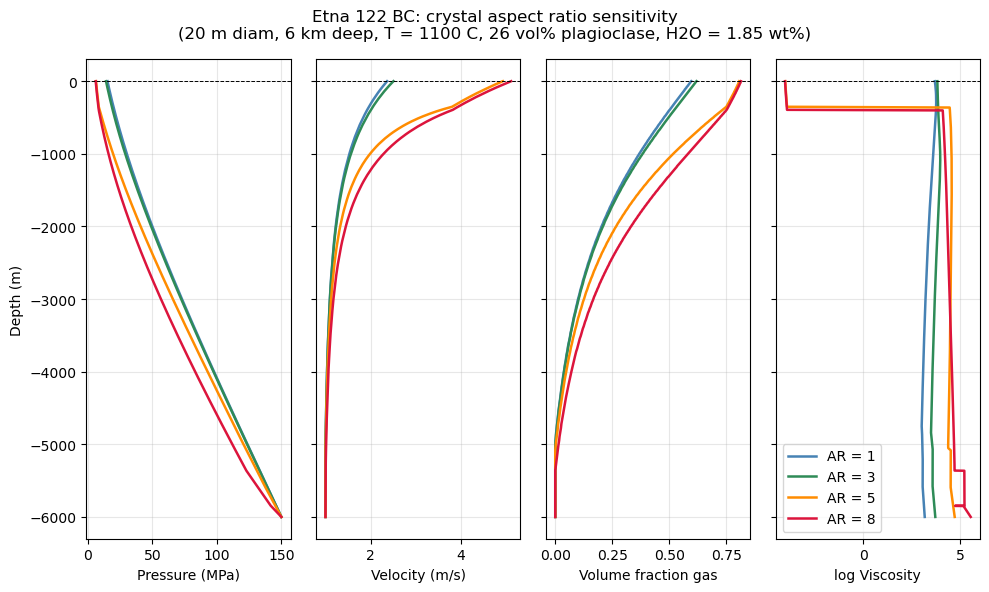

Figure saved as etna_AR_sensitivity.png


In [26]:
fig, axes = plt.subplots(1, 4, figsize=(10, 6), sharey=True)
fig.suptitle(
    'Etna 122 BC: crystal aspect ratio sensitivity\n'
    '(20 m diam, 6 km deep, T = 1100 C, 26 vol% plagioclase, H2O = 1.85 wt%)',
    fontsize=12
)
ar_colors = {1: 'steelblue', 3: 'seagreen', 5: 'darkorange', 8: 'crimson'}

# For each subplot, plot one line per aspect ratio
for ax, (var, xlabel) in zip(axes, plot_vars):
    for ar, df in dfs_ar.items():
        ax.plot(df[var], df['z (m)'], label=f'AR = {ar}', color=ar_colors[ar], linewidth=1.8)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3)
    ax.axhline(0, color='k', linewidth=0.7, linestyle='--')

axes[0].set_ylabel('Depth (m)', fontsize=10)
axes[3].legend(fontsize=10, loc='lower left')
plt.tight_layout()
plt.savefig('etna_AR_sensitivity.png', dpi=150)
plt.show()
print('Figure saved as etna_AR_sensitivity.png')

## Discussion questions: aspect ratio sensitivity

1. How does increasing aspect ratio affect viscosity along the conduit?
2. The AR = 1 run is equivalent to what the original Conflow (Einstein-Roscoe) would produce. How different are the results at AR = 5 or 8?